In [1]:
# ==============================================================================
# STEP 1: INSTALL & SETUP
# ==============================================================================
import os
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 2. Install Dependencies (Quietly)
print("⏳ Installing libraries... (This takes ~2 mins)")
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps xformers "trl<0.9.0" peft accelerate bitsandbytes
!pip install -q evaluate jiwer sacrebleu seaborn matplotlib

⏳ Installing libraries... (This takes ~2 mins)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.6/289.6 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 136.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.9/224.9 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.2/245.2 kB 25.6 MB/s eta 0:00:00
     ━━━━━━━━━━━

In [3]:
# 3. Imports
import torch
from unsloth import FastLanguageModel
from datasets import load_dataset
from trl import SFTTrainer
from transformers import TrainingArguments, TextStreamer
import numpy as np
import pandas as pd
import evaluate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import re

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [5]:
# ==============================================================================
# STEP 2: CONFIGURATION & MODEL LOADING
# ==============================================================================

# --- PATHS (UPDATED FOR INTERROGATIVE TRAINING) ---
# 1. Load the model you just trained (Assertive Sentences)
prev_model_path = "/content/drive/MyDrive/Marma_AssertiveSentence_Model_Final"
# 2. Load the new Question dataset
dataset_path = "/content/drive/MyDrive/dataset/marma_interrogative_dataset.jsonl"
# 3. Save the new Question model here
final_save_path = "/content/drive/MyDrive/Marma_Interrogative_Model_Final"

# CONFIG
max_seq_length = 2048
load_in_4bit = True

print(f"🔄 Loading Pre-trained Model from: {prev_model_path}")

# Load the model (This loads LLaMA + Your Assertive Adapters)
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = prev_model_path,
    max_seq_length = max_seq_length,
    dtype = None,
    load_in_4bit = load_in_4bit,
)

# Apply PEFT (LoRA) for Training
# We continue fine-tuning the adapters
# The model already has LoRA adapters loaded from prev_model_path, so re-applying them is not needed.
# model = FastLanguageModel.get_peft_model(
#     model,
#     r = 16,
#     target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
#                       "gate_proj", "up_proj", "down_proj",],
#     lora_alpha = 16,
#     lora_dropout = 0.05,
#     bias = "none",
#     use_gradient_checkpointing = "unsloth",
#     random_state = 3407,
#     use_rslora = False,
#     loftq_config = None,
# )

🔄 Loading Pre-trained Model from: /content/drive/MyDrive/Marma_AssertiveSentence_Model_Final
==((====))==  Unsloth 2025.12.7: Fast Llama patching. Transformers: 4.57.3.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.161 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.0+cu126. CUDA: 8.9. CUDA Toolkit: 12.6. Triton: 3.5.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


In [6]:
# ==============================================================================
# STEP 3: DATA PROCESSING & FILTERING
# ==============================================================================

print("📂 Loading and Cleaning Dataset...")
try:
    dataset = load_dataset("json", data_files=dataset_path, split="train")
except ValueError:
    print(f"❌ Error: Could not find dataset at {dataset_path}")
    print("Please make sure you ran the Data Cleaning code first!")
    raise

# FILTER: Remove "Marma <-> Marma" translations (Same logic as before)
def filter_marma_marma(example):
    inst = example['instruction']
    if "this Marma" in inst and "into Marma" in inst:
        return False
    return True

original_len = len(dataset)
dataset = dataset.filter(filter_marma_marma)
print(f"Original Rows: {original_len} | Filtered Rows: {len(dataset)} (Removed Marma-to-Marma)")

# Split Data: 95% Train, 5% Test
dataset = dataset.train_test_split(test_size=0.05, seed=3407)

alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + tokenizer.eos_token
        texts.append(text)
    return { "text" : texts, }

train_dataset = dataset["train"].map(formatting_prompts_func, batched = True)
test_dataset  = dataset["test"].map(formatting_prompts_func, batched = True)

📂 Loading and Cleaning Dataset...


Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/15816 [00:00<?, ? examples/s]

Original Rows: 15816 | Filtered Rows: 13180 (Removed Marma-to-Marma)


Map:   0%|          | 0/12521 [00:00<?, ? examples/s]

Map:   0%|          | 0/659 [00:00<?, ? examples/s]

In [7]:
# ==============================================================================
# STEP 4: TRAINING
# ==============================================================================

print("🚀 Starting Interrogative Training...")

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = test_dataset, # Monitor validation
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 4,
        gradient_accumulation_steps = 4,
        warmup_steps = 50, # Reduced warmup slightly for smaller dataset

        # 1 Epoch is usually enough for fine-tuning on top of an existing model
        num_train_epochs = 1,

        learning_rate = 2e-4,
        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),

        logging_steps = 50,
        eval_strategy = "steps",
        eval_steps = 50,

        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        save_strategy = "no",
    ),
)

trainer.train()

# SAVE MODEL IMMEDIATELY
print(f"💾 Saving Final Question Model to {final_save_path}...")
model.save_pretrained(final_save_path)
tokenizer.save_pretrained(final_save_path)
print("✅ Model Saved.")

🚀 Starting Interrogative Training...


Map (num_proc=2):   0%|          | 0/12521 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/659 [00:00<?, ? examples/s]

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 12,521 | Num Epochs = 1 | Total steps = 783
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

... (3 outputs left out)

Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
50,0.548200,0.463860
100,0.413400,0.427637
150,0.404900,0.403408
200,0.373200,0.384028
250,0.360800,0.365294
300,0.352600,0.346804
350,0.323200,0.334267
400,0.316300,0.319279
450,0.302700,0.301063
500,0.285700,0.288118


Unsloth: Not an error, but LlamaForCausalLM does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


💾 Saving Final Question Model to /content/drive/MyDrive/Marma_Interrogative_Model_Final...
✅ Model Saved.


In [8]:
# ==============================================================================
# STEP 5: MULTI-METRIC EVALUATION BY DIRECTION
# ==============================================================================

print("\n📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...")

# Load Metrics
bleu = evaluate.load("sacrebleu")
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

def normalize(text):
    # Updated normalize to handle '?' and '।'
    return text.lower().strip().replace(".", "").replace("।", "").replace("?", "")

def get_direction(instruction):
    try:
        src = re.search(r"Translate this (.*?) sentence", instruction).group(1)
        tgt = re.search(r"into (.*?)\.", instruction).group(1)
        return f"{src} -> {tgt}"
    except:
        return "Unknown"

results_log = []
FastLanguageModel.for_inference(model)

# Evaluate on TEST SET
# Since dataset is small (~15,000 rows total), test set is small (~750). We can run full test.
eval_subset = test_dataset

print(f"Evaluating {len(eval_subset)} samples...")

for item in tqdm(eval_subset, desc="Evaluating"):
    full_text = item["text"]
    prompt = full_text.split("### Response:\n")[0] + "### Response:\n"
    reference = full_text.split("### Response:\n")[1].replace(tokenizer.eos_token, "").strip()

    instruction = item["instruction"]
    direction = get_direction(instruction)

    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    outputs = model.generate(**inputs, max_new_tokens=128, use_cache=True)
    prediction = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    prediction = prediction.split("### Response:\n")[-1].strip()

    results_log.append({
        "direction": direction,
        "reference": reference,
        "prediction": prediction
    })


📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...


Evaluating 659 samples...


Evaluating:   0%|          | 0/659 [00:00<?, ?it/s]

In [9]:
# ==============================================================================
# STEP 6: CALCULATE & PLOT SCORES
# ==============================================================================

df_res = pd.DataFrame(results_log)
summary = []
unique_directions = df_res['direction'].unique()

print("\n" + "="*60)
print(f"{'DIRECTION':<40} | {'BLEU':<6} | {'WER':<6} | {'CER':<6} | {'ACC':<6}")
print("="*60)

for direction in unique_directions:
    subset = df_res[df_res['direction'] == direction]
    if len(subset) == 0: continue

    refs = subset['reference'].tolist()
    preds = subset['prediction'].tolist()

    bleu_score = bleu.compute(predictions=preds, references=refs)['score']
    wer_score = wer_metric.compute(predictions=preds, references=refs)
    cer_score = cer_metric.compute(predictions=preds, references=refs)

    exact_matches = sum([1 for p, r in zip(preds, refs) if normalize(p) == normalize(r)])
    accuracy = (exact_matches / len(preds)) * 100

    summary.append({
        "Direction": direction,
        "BLEU": bleu_score,
        "WER": wer_score,
        "CER": cer_score,
        "Accuracy": accuracy
    })

    print(f"{direction:<40} | {bleu_score:>6.2f} | {wer_score:>6.2f} | {cer_score:>6.2f} | {accuracy:>6.1f}%")

print("="*60)


DIRECTION                                | BLEU   | WER    | CER    | ACC   
English -> Marma (Bangla Script)         |  21.52 |   0.82 |   0.51 |    7.4%
Marma (English Script) -> Bangla         |  33.28 |   0.57 |   0.43 |   18.6%
Marma (Bangla Script) -> English         |  46.57 |   0.43 |   0.31 |   28.6%
Marma (English Script) -> English        |  44.35 |   0.44 |   0.33 |   30.6%
English -> Bangla                        |  64.57 |   0.25 |   0.17 |   50.0%
Bangla -> Marma (English Script)         |   7.95 |   0.83 |   0.50 |    7.8%
Marma (Bangla Script) -> Bangla          |  43.50 |   0.50 |   0.38 |   35.8%
Bangla -> Marma (Bangla Script)          |  25.64 |   0.73 |   0.44 |   10.6%
English -> Marma (English Script)        |  15.74 |   0.81 |   0.45 |    8.6%
Bangla -> English                        |  74.68 |   0.19 |   0.12 |   61.7%


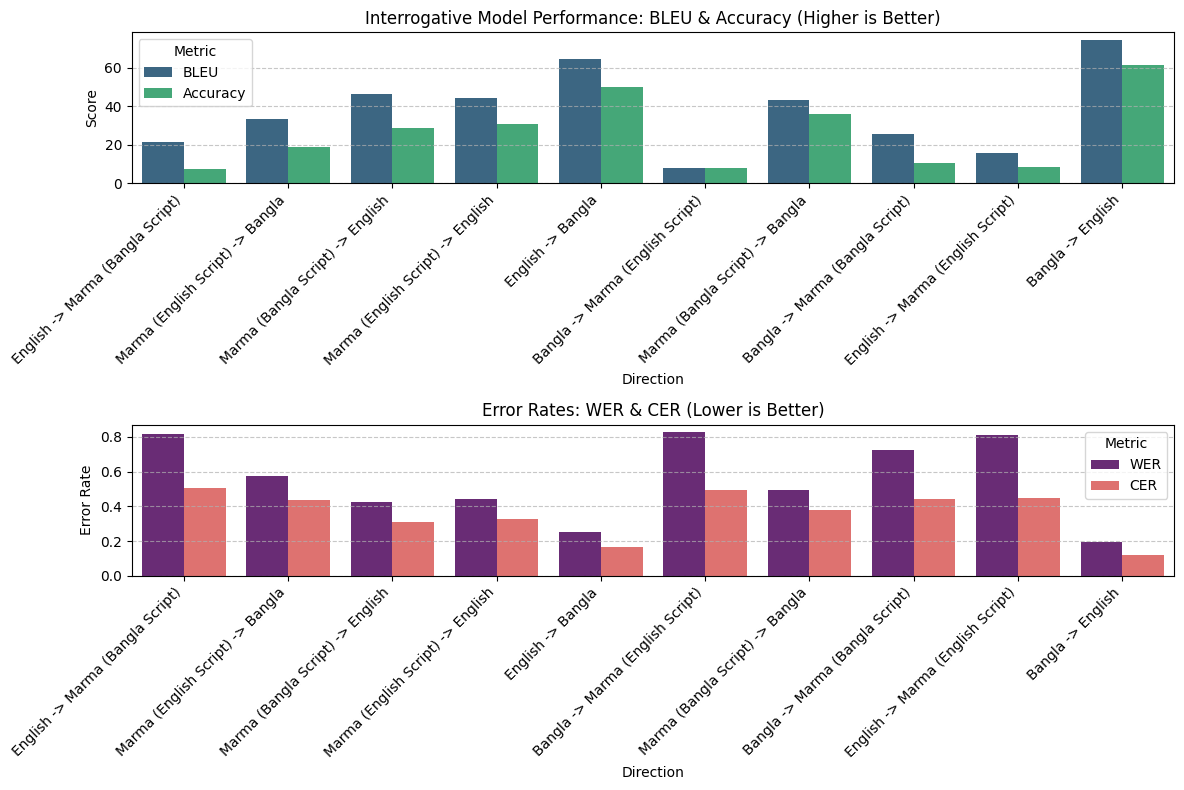


✅ PROCESS COMPLETE. Model saved and evaluation finished.


In [10]:
# ==============================================================================
# STEP 7: VISUALIZATION
# ==============================================================================

if len(summary) > 0:
    df_viz = pd.DataFrame(summary)

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 1, 1)
    df_melt_high = df_viz.melt(id_vars="Direction", value_vars=["BLEU", "Accuracy"], var_name="Metric", value_name="Score")
    sns.barplot(data=df_melt_high, x="Direction", y="Score", hue="Metric", palette="viridis")
    plt.title("Interrogative Model Performance: BLEU & Accuracy (Higher is Better)")
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.subplot(2, 1, 2)
    df_melt_low = df_viz.melt(id_vars="Direction", value_vars=["WER", "CER"], var_name="Metric", value_name="Error Rate")
    sns.barplot(data=df_melt_low, x="Direction", y="Error Rate", hue="Metric", palette="magma")
    plt.title("Error Rates: WER & CER (Lower is Better)")
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No data to visualize.")

print("\n✅ PROCESS COMPLETE. Model saved and evaluation finished.")